In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

def leveraged_return(daily_ret, leverage, expense_ratio=0.0095, borrow_spread=0.01):
    """Synthetic daily-reset leveraged return: leverage*underlying_return - (ER + (lev-1)*borrow spread)/252."""
    daily_cost = expense_ratio / 252 + (leverage - 1) * borrow_spread / 252
    return leverage * daily_ret - daily_cost

def get_prices(ticker, start=None, end=None):
    if start is None:
        start = '1990-01-01'  # earlier than any relevant inception; yfinance clips automatically
    if end is None:
        end = pd.Timestamp.today().strftime('%Y-%m-%d')
    df = yf.download(ticker, start=start, end=end, auto_adjust=True, progress=False)
    if df.empty:
        raise ValueError(f"No data returned for {ticker}")
    close = df['Close']
    if isinstance(close, pd.DataFrame):  # guard against multi-level columns for single ticker
        close = close.iloc[:, 0]
    return close.dropna()

def compute_hedge_returns(hedge_weights, index, start=None, end=None,
                           tbill_ticker='BIL', apply_leverage_cost=True,
                           expense_ratio=0.0095, borrow_spread=0.01):
    """
    hedge_weights values are exposure multipliers, not normalized portfolio weights.
    e.g. {'TLT': 1.0, 'QQQ': -1.5} = full long TLT + synthetic -1.5x QQQ short.
    Missing-data days for a given ticker contribute 0 exposure (not rescaled).
    Falls back to T-bill proxy return only when ALL components are missing that day.
    """
    rets = {}
    for tkr, w in hedge_weights.items():
        px = get_prices(tkr, start=start, end=end).reindex(index)
        r = px.pct_change()
        if apply_leverage_cost:
            cost = expense_ratio / 252 + max(abs(w) - 1, 0) * borrow_spread / 252
            r = w * r - cost
        else:
            r = w * r
        rets[tkr] = r

    rets_df = pd.DataFrame(rets)
    avail = pd.DataFrame({tkr: get_prices(tkr, start=start, end=end).reindex(index).notna()
                           for tkr in hedge_weights})
    any_data = avail.any(axis=1)
    hedge_ret = rets_df.fillna(0).sum(axis=1)

    no_hedge_data = ~any_data
    if no_hedge_data.any():
        try:
            tbill_px = get_prices(tbill_ticker, start=start, end=end).reindex(index).ffill()
            tbill_ret = tbill_px.pct_change().fillna(0)
        except ValueError:
            tbill_ret = pd.Series(0.02 / 252, index=index)
        hedge_ret[no_hedge_data] = tbill_ret[no_hedge_data]

    return hedge_ret
def max_drawdown_and_duration(value_series):
    running_max = value_series.cummax()
    drawdown = value_series / running_max - 1
    max_dd = drawdown.min()
    underwater = drawdown < 0
    durations, start = [], None
    for date, uw in underwater.items():
        if uw and start is None:
            start = date
        elif not uw and start is not None:
            durations.append((date - start).days)
            start = None
    if start is not None:
        durations.append((underwater.index[-1] - start).days)
    max_dd_days = max(durations) if durations else 0
    return max_dd, max_dd_days, drawdown

def perf_stats(value_series):
    rets = value_series.pct_change().dropna()
    n_years = (value_series.index[-1] - value_series.index[0]).days / 365.25
    cagr = (value_series.iloc[-1] / value_series.iloc[0]) ** (1 / n_years) - 1
    ann_vol = rets.std() * np.sqrt(252)
    downside = rets[rets < 0]
    downside_std = downside.std() * np.sqrt(252) if len(downside) else np.nan
    sortino = (rets.mean() * 252) / downside_std if downside_std else np.nan
    sharpe = (rets.mean() * 252) / ann_vol if ann_vol else np.nan
    max_dd, max_dd_days, dd_series = max_drawdown_and_duration(value_series)
    return {
        'CAGR': cagr, 'Ann. Vol': ann_vol, 'Sortino': sortino, 'Sharpe': sharpe,
        'Max Drawdown': max_dd, 'Max DD Duration (days)': max_dd_days,
        'Final Value': value_series.iloc[-1],
    }, dd_series

def run_strategy(
    base_ticker='QQQ',
    leverage=2.0,
    rearm_leverage=3.0,
    hedge_weights={'PSQ': 1.0},
    sma_windows=(200, 250),
    off_days_threshold=20,
    rearm_days=90,
    start_date=None,
    end_date=None,
    dca_amount=0.0,
    initial_capital=10000.0,
    expense_ratio=0.0095,
    borrow_spread=0.01,
    baseline_ticker='SPY',
):
    qqq = get_prices(base_ticker, start=start_date, end=end_date)
    qqq_ret = qqq.pct_change()
    sma_a = qqq.rolling(sma_windows[0]).mean()
    sma_b = qqq.rolling(sma_windows[1]).mean()

    valid_from = max(sma_a.first_valid_index(), sma_b.first_valid_index())
    idx = qqq.index[qqq.index >= valid_from]

    hedge_ret = compute_hedge_returns(hedge_weights, idx, start=start_date, end=end_date)

    month_end_flags = pd.Series(idx, index=idx).groupby([idx.year, idx.month]).transform('max') == idx

    prev_is_on = None
    consecutive_off = 0
    rearm_remaining = 0
    modes, strat_rets = [], []

    for date in idx:
        r_qqq = qqq_ret.loc[date]
        prev_close, prev_a, prev_b = qqq.shift(1), sma_a.shift(1), sma_b.shift(1)
        is_on = bool(prev_close.loc[date] > prev_a.loc[date] and prev_close.loc[date] > prev_b.loc[date])
        # is_on = bool(qqq.loc[date] > sma_a.loc[date] and qqq.loc[date] > sma_b.loc[date])
        if is_on:
            if prev_is_on is False and consecutive_off >= off_days_threshold:
                rearm_remaining = rearm_days
            consecutive_off = 0
            if rearm_remaining > 0:
                mode, lev = 'REARM', rearm_leverage
                rearm_remaining -= 1
            else:
                mode, lev = 'ON', leverage
            ret = leveraged_return(r_qqq, lev, expense_ratio, borrow_spread)
        else:
            mode = 'OFF'
            consecutive_off += 1
            rearm_remaining = 0
            ret = hedge_ret.loc[date]
        modes.append(mode)
        strat_rets.append(ret)
        prev_is_on = is_on

    modes = pd.Series(modes, index=idx)
    strat_rets = pd.Series(strat_rets, index=idx).fillna(0)

    def build_value(rets, dca_flags):
        value = initial_capital
        values = []
        for date in rets.index:
            if dca_flags.loc[date] and date != rets.index[0]:
                value += dca_amount
            value *= (1 + rets.loc[date])
            values.append(value)
        return pd.Series(values, index=rets.index)

    strat_value = build_value(strat_rets, month_end_flags)

    baseline_px = get_prices(baseline_ticker, start=start_date, end=end_date).reindex(idx).ffill()
    baseline_ret = baseline_px.pct_change().fillna(0)
    baseline_value = build_value(baseline_ret, month_end_flags)

    strat_stats, strat_dd = perf_stats(strat_value)
    base_stats, base_dd = perf_stats(baseline_value)

    stats_df = pd.DataFrame({
        f'Strategy ({base_ticker} {leverage}x/{rearm_leverage}x)': strat_stats,
        f'Baseline ({baseline_ticker})': base_stats,
    })
    print(stats_df.to_string(float_format=lambda x: f'{x:,.3f}' if abs(x) < 100 else f'{x:,.0f}'))

    fig, ax = plt.subplots(figsize=(14, 7))
    ax.plot(strat_value.index, strat_value.values, label='Strategy', color='tab:blue', linewidth=1.3)
    ax.plot(baseline_value.index, baseline_value.values, label=f'Baseline ({baseline_ticker})',
             color='tab:gray', linewidth=1.0, alpha=0.8)
    ax.set_yscale('log')
    ax.set_ylabel('Portfolio Value ($, log scale)')
    ax.set_title(f'{base_ticker}-based Leverage Rotation Strategy vs {baseline_ticker}')

    def shade_periods(mask, color, label):
        in_run, start, labeled = False, None, False
        for date, flag in mask.items():
            if flag and not in_run:
                start, in_run = date, True
            elif not flag and in_run:
                ax.axvspan(start, date, color=color, alpha=0.15, label=label if not labeled else None)
                labeled, in_run = True, False
        if in_run:
            ax.axvspan(start, mask.index[-1], color=color, alpha=0.15, label=label if not labeled else None)

    shade_periods(modes == 'OFF', 'red', 'OFF (hedge)')
    shade_periods(modes == 'REARM', 'orange', 'REARM')

    ax.legend(loc='upper left')
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return {
        'strategy_value': strat_value, 'baseline_value': baseline_value,
        'modes': modes, 'stats': stats_df,
        'strategy_drawdown': strat_dd, 'baseline_drawdown': base_dd,
    }

                        Strategy (QQQ 2x/3.0x)  Baseline (QQQ)
CAGR                                     0.204           0.220
Ann. Vol                                 0.390           0.272
Sortino                                  0.892           1.167
Sharpe                                   0.672           0.868
Max Drawdown                            -0.607          -0.509
Max DD Duration (days)                   1,269             746
Final Value                          1,385,477       1,977,892


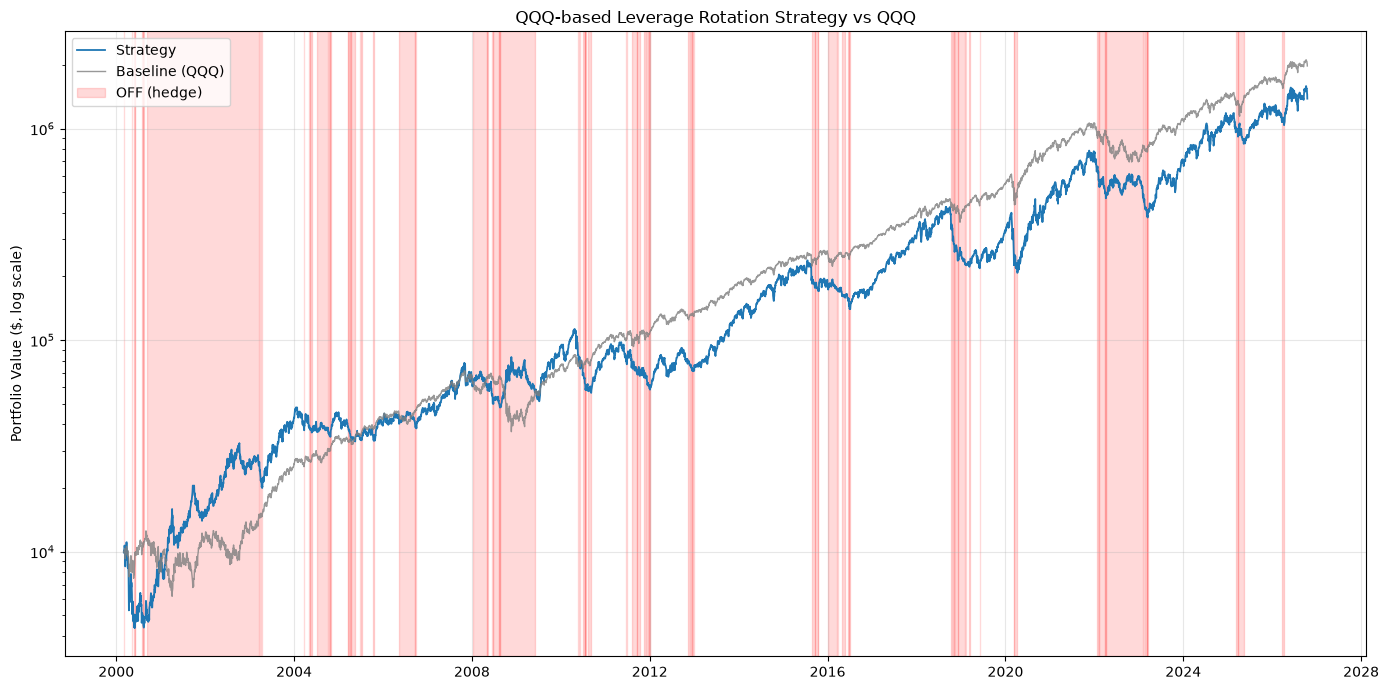

In [6]:
results = run_strategy(
    base_ticker='QQQ',
    leverage=2,             # QLD-equivalent steady state
    rearm_leverage=3.0,       # TQQQ-equivalent during rearm window
    hedge_weights={'QQQ': -1},
    sma_windows=(200, 250),
    off_days_threshold=20,
    rearm_days=0,
    start_date=None,          # since QQQ inception (1999-03-10)
    end_date=None,            # through today
    dca_amount=500,           # monthly end-of-month contribution
    initial_capital=10000,
    baseline_ticker='QQQ',
)

ON       4474
OFF      1835
REARM     333
Name: count, dtype: int64

% of days OFF: 27.6%
% of days REARM: 5.0%
ON: n=4474, corr with QQQ = 0.998
OFF: n=1835, corr with QQQ = -0.999
REARM: n=333, corr with QQQ = 1.000

Sample OFF period: 2000-05-10 00:00:00 to 2026-04-07 00:00:00


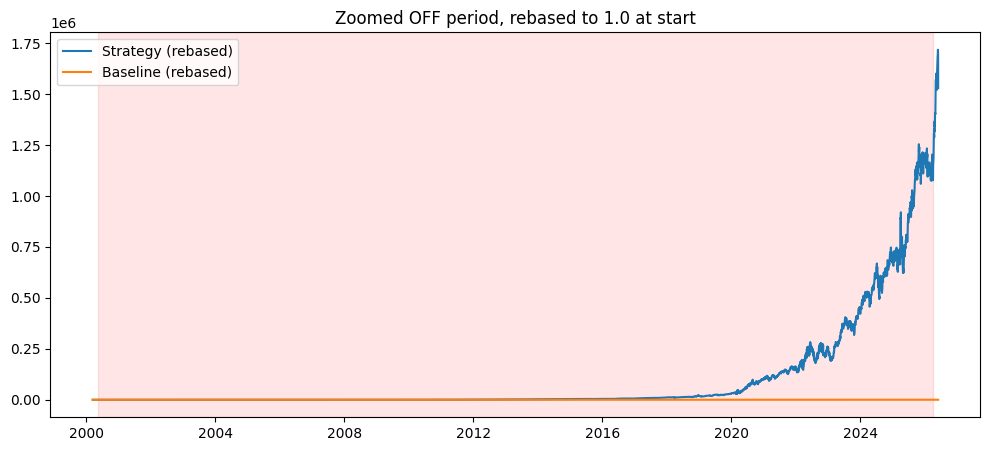

In [44]:
modes = results['modes']
print(modes.value_counts())
print(f"\n% of days OFF: {(modes == 'OFF').mean():.1%}")
print(f"% of days REARM: {(modes == 'REARM').mean():.1%}")

# correlation of daily returns split by mode
strat_daily_ret = results['strategy_value'].pct_change()
qqq_daily_ret = get_prices('QQQ').reindex(strat_daily_ret.index).pct_change()

for m in ['ON', 'OFF', 'REARM']:
    mask = modes == m
    if mask.sum() > 5:
        corr = strat_daily_ret[mask].corr(qqq_daily_ret[mask])
        print(f"{m}: n={mask.sum()}, corr with QQQ = {corr:.3f}")

# zoom into a specific OFF period to actually see divergence, e.g. 2022
off_dates = modes[modes == 'OFF'].index
if len(off_dates) > 0:
    # pick the longest contiguous OFF stretch to zoom into
    print(f"\nSample OFF period: {off_dates[0]} to {off_dates[-1]}")
    zoom_start, zoom_end = off_dates[0] - pd.Timedelta(days=60), off_dates[-1] + pd.Timedelta(days=60)
    fig, ax = plt.subplots(figsize=(12, 5))
    zoomed_strat = results['strategy_value'].loc[zoom_start:zoom_end]
    zoomed_base = results['baseline_value'].loc[zoom_start:zoom_end]
    ax.plot(zoomed_strat / zoomed_strat.iloc[0], label='Strategy (rebased)')
    ax.plot(zoomed_base / zoomed_base.iloc[0], label='Baseline (rebased)')
    ax.axvspan(off_dates[0], off_dates[-1], color='red', alpha=0.1)
    ax.legend(); ax.set_title('Zoomed OFF period, rebased to 1.0 at start')
    plt.show()

In [55]:
import itertools
from itertools import combinations
from scipy.stats import norm, skew, kurtosis

# ============================================================
# 0. Price caching — grid search will re-hit the same tickers
#    dozens of times, so cache instead of re-downloading each time
# ============================================================
_price_cache = {}
def get_prices_cached(ticker, start=None, end=None):
    key = (ticker, start, end)
    if key not in _price_cache:
        _price_cache[key] = get_prices(ticker, start=start, end=end)
    return _price_cache[key]

# ============================================================
# 1. Lightweight engine: returns-only, no DCA, no plotting
#    (DCA distorts pure return-based Sortino/CAGR comparisons
#    across configs, so grid search runs on raw compounding only)
# ============================================================
def compute_strategy_returns(base_ticker='QQQ', leverage=2.0, rearm_leverage=3.0,
                              hedge_weights={'PSQ': 1.0}, sma_windows=(200, 250),
                              off_days_threshold=20, rearm_days=90,
                              start_date=None, end_date=None,
                              expense_ratio=0.0095, borrow_spread=0.01):
    qqq = get_prices_cached(base_ticker, start=start_date, end=end_date)
    qqq_ret = qqq.pct_change()
    sma_a = qqq.rolling(sma_windows[0]).mean()
    sma_b = qqq.rolling(sma_windows[1]).mean()
    valid_from = max(sma_a.first_valid_index(), sma_b.first_valid_index())
    idx = qqq.index[qqq.index >= valid_from]

    hedge_ret = compute_hedge_returns(hedge_weights, idx, start=start_date, end=end_date,
                                       expense_ratio=expense_ratio, borrow_spread=borrow_spread)

    prev_is_on, consecutive_off, rearm_remaining = None, 0, 0
    modes, strat_rets = [], []
    for date in idx:
        r_qqq = qqq_ret.loc[date]
        is_on = bool(qqq.loc[date] > sma_a.loc[date] and qqq.loc[date] > sma_b.loc[date])
        if is_on:
            if prev_is_on is False and consecutive_off >= off_days_threshold:
                rearm_remaining = rearm_days
            consecutive_off = 0
            if rearm_remaining > 0:
                mode, lev = 'REARM', rearm_leverage
                rearm_remaining -= 1
            else:
                mode, lev = 'ON', leverage
            ret = leveraged_return(r_qqq, lev, expense_ratio, borrow_spread)
        else:
            mode = 'OFF'
            consecutive_off += 1
            rearm_remaining = 0
            ret = hedge_ret.loc[date]
        modes.append(mode)
        strat_rets.append(ret)
        prev_is_on = is_on
    return pd.Series(strat_rets, index=idx).fillna(0), pd.Series(modes, index=idx)

# ============================================================
# 2. PARAMETER SENSITIVITY GRID
#    Tests whether your best result is a robust plateau or an
#    isolated spike in parameter space
# ============================================================
def run_grid_search(base_ticker='QQQ',
                     sma_grid=[(150, 200), (180, 220), (200, 250), (220, 280), (250, 300)],
                     leverage_grid=[(1.5, 2.0), (2.0, 3.0), (2.5, 3.0), (3.0, 3.0)],
                     hedge_options={'PSQ': {'PSQ': 1.0}, 'QID_synth': {'QQQ': -2.0}, 'SQQQ_synth': {'QQQ': -3.0}},
                     start_date=None, end_date=None):
    records, returns_dict = [], {}
    for sma_pair in sma_grid:
        for lev_pair in leverage_grid:
            for hedge_name, hedge_w in hedge_options.items():
                key = f"sma{sma_pair}_lev{lev_pair}_{hedge_name}"
                rets, modes = compute_strategy_returns(
                    base_ticker=base_ticker, leverage=lev_pair[0], rearm_leverage=lev_pair[1],
                    hedge_weights=hedge_w, sma_windows=sma_pair,
                    start_date=start_date, end_date=end_date)
                value = (1 + rets).cumprod() * 10000
                stats, _ = perf_stats(value)
                stats.update({'config': key, 'sma': sma_pair, 'leverage': lev_pair, 'hedge': hedge_name})
                records.append(stats)
                returns_dict[key] = rets
    grid_df = pd.DataFrame(records).set_index('config')
    return grid_df.sort_values('Sortino', ascending=False), returns_dict

# ============================================================
# 3. WALK-FORWARD SPLIT
#    Since no parameters are literally curve-fit, this isn't a
#    classic in/out-of-sample test — it's a check for whether
#    performance is concentrated in one era (e.g. 2009-2021 ZIRP)
#    vs holding up in both halves independently
# ============================================================
def walk_forward_report(rets, split_date):
    pre, post = rets[rets.index < split_date], rets[rets.index >= split_date]
    pre_val = (1 + pre).cumprod() * 10000
    post_val = (1 + post).cumprod() * 10000
    pre_stats, _ = perf_stats(pre_val)
    post_stats, _ = perf_stats(post_val)
    return pd.DataFrame({f'Pre {split_date}': pre_stats, f'Post {split_date}': post_stats})

# ============================================================
# 4. BLOCK BOOTSTRAP CONFIDENCE INTERVAL
#    Resamples 20-day blocks (preserves autocorrelation/regime
#    clustering) to get a distribution around Sortino/CAGR
#    instead of trusting the single realized-path point estimate
# ============================================================
def block_bootstrap_ci(rets, n_boot=1000, block_size=20, ci=(5, 95), seed=42):
    rng = np.random.default_rng(seed)
    n = len(rets)
    n_blocks = int(np.ceil(n / block_size))
    rets_arr = rets.values
    sortino_samples, cagr_samples = [], []
    for _ in range(n_boot):
        idxs = rng.integers(0, n - block_size, size=n_blocks)
        sample = np.concatenate([rets_arr[i:i + block_size] for i in idxs])[:n]
        value = np.cumprod(1 + sample) * 10000
        years = n / 252
        cagr = (value[-1] / value[0]) ** (1 / years) - 1
        downside = sample[sample < 0]
        downside_std = downside.std() * np.sqrt(252) if len(downside) else np.nan
        sortino = (sample.mean() * 252) / downside_std if downside_std else np.nan
        sortino_samples.append(sortino)
        cagr_samples.append(cagr)
    sortino_samples, cagr_samples = np.array(sortino_samples), np.array(cagr_samples)
    result = {
        'Sortino median': np.nanmedian(sortino_samples),
        f'Sortino {ci[0]}%': np.nanpercentile(sortino_samples, ci[0]),
        f'Sortino {ci[1]}%': np.nanpercentile(sortino_samples, ci[1]),
        'CAGR median': np.nanmedian(cagr_samples),
        f'CAGR {ci[0]}%': np.nanpercentile(cagr_samples, ci[0]),
        f'CAGR {ci[1]}%': np.nanpercentile(cagr_samples, ci[1]),
    }
    return result, sortino_samples, cagr_samples

# ============================================================
# 5. DEFLATED SHARPE RATIO (Bailey & López de Prado)
#    Penalizes the best-of-N-trials Sharpe for the fact that you
#    tried N configs and picked the winner — tells you the odds
#    the "best" result is real skill vs the expected max of noise
# ============================================================
def deflated_sharpe_ratio(observed_sharpe, all_trial_sharpes, returns_for_moments, T):
    N = len(all_trial_sharpes)
    trial_var = np.var(all_trial_sharpes, ddof=1)
    gamma = 0.5772156649
    sr0 = (np.sqrt(trial_var) * ((1 - gamma) * norm.ppf(1 - 1 / N) + gamma * norm.ppf(1 - 1 / (N * np.e)))
           if N > 1 and trial_var > 0 else 0.0)
    skw = skew(returns_for_moments)
    krt = kurtosis(returns_for_moments, fisher=False)
    denom = np.sqrt(max(1 - skw * observed_sharpe + (krt - 1) / 4 * observed_sharpe ** 2, 1e-8))
    z = (observed_sharpe - sr0) * np.sqrt(T - 1) / denom
    return norm.cdf(z), sr0  # DSR close to 1.0 = high confidence skill isn't just noise

# ============================================================
# 6. PROBABILITY OF BACKTEST OVERFITTING (CSCV, Bailey et al.)
#    Splits history into blocks, tries every combo of "in-sample"
#    vs "out-of-sample" halves, and checks how often the in-sample
#    best performer is actually below-median out-of-sample
# ============================================================
def compute_pbo(returns_dict, n_splits=10, max_combos=200):
    common_idx = None
    for r in returns_dict.values():
        common_idx = r.index if common_idx is None else common_idx.intersection(r.index)
    df = pd.DataFrame({k: v.reindex(common_idx) for k, v in returns_dict.items()}).dropna()
    n = len(df)
    splits = np.array_split(np.arange(n), n_splits)

    def sharpe(x):
        return x.mean() / x.std() if x.std() > 0 else -np.inf

    half = n_splits // 2
    all_combos = list(combinations(range(n_splits), half))
    rng = np.random.default_rng(0)
    if len(all_combos) > max_combos:
        idxs = rng.choice(len(all_combos), max_combos, replace=False)
        all_combos = [all_combos[i] for i in idxs]

    logits = []
    for combo in all_combos:
        is_idx = np.concatenate([splits[i] for i in combo])
        oos_idx = np.concatenate([splits[i] for i in range(n_splits) if i not in combo])
        is_perf = df.iloc[is_idx].apply(sharpe)
        oos_perf = df.iloc[oos_idx].apply(sharpe)
        best_is_config = is_perf.idxmax()
        oos_rank = oos_perf.rank(pct=True)[best_is_config]
        logit = 10.0 if oos_rank >= 1 else (-10.0 if oos_rank <= 0 else np.log(oos_rank / (1 - oos_rank)))
        logits.append(logit)
    pbo = np.mean(np.array(logits) < 0)  # fraction of trials where "best in-sample" underperformed OOS
    return pbo, logits

In [57]:
# 1. Grid sensitivity — is the (200,250)/2.5x/PSQ result a plateau or a spike?
grid_df, returns_dict = run_grid_search(
    sma_grid=[(150,200), (180,220), (200,250), (220,280), (250,300)],
    leverage_grid=[(1.5,2.0), (2.0,3.0), (2.5,3.0), (3.0,3.0)],
    hedge_options={'PSQ': {'PSQ': 1.0}, 'QID_synth': {'QQQ': -2.0}, 'SQQQ_synth': {'QQQ': -3.0}},
)
print(grid_df[['Sortino', 'CAGR', 'Max Drawdown', 'Max DD Duration (days)']].head(15))

# 2. Walk-forward — does your best config hold up pre/post 2015?
best_key = grid_df.index[0]
print(f"\nWalk-forward for {best_key}:")
print(walk_forward_report(returns_dict[best_key], split_date='2015-01-01'))

# 3. Block bootstrap CI on the best config
ci_result, _, _ = block_bootstrap_ci(returns_dict[best_key], n_boot=1000)
print(f"\nBootstrap CI for {best_key}:", ci_result)

# 4. Deflated Sharpe Ratio across all grid trials
trial_sharpes = {k: v.mean()/v.std() for k, v in returns_dict.items()}
best_sharpe_key = max(trial_sharpes, key=trial_sharpes.get)
dsr, sr0 = deflated_sharpe_ratio(
    trial_sharpes[best_sharpe_key], list(trial_sharpes.values()),
    returns_dict[best_sharpe_key].values, len(returns_dict[best_sharpe_key])
)
print(f"\nDSR for {best_sharpe_key}: {dsr:.4f}  (expected max Sharpe under noise, SR0={sr0:.4f})")

# 5. PBO across the full grid
pbo, _ = compute_pbo(returns_dict)
print(f"\nProbability of Backtest Overfitting: {pbo:.2%}")

                                        Sortino      CAGR  Max Drawdown  \
config                                                                    
sma(150, 200)_lev(2.0, 3.0)_PSQ        2.085371  0.683724     -0.453635   
sma(150, 200)_lev(3.0, 3.0)_QID_synth  2.075229  1.198465     -0.631052   
sma(150, 200)_lev(2.5, 3.0)_PSQ        2.069112  0.823159     -0.536679   
sma(150, 200)_lev(3.0, 3.0)_PSQ        2.036418  0.962388     -0.609474   
sma(150, 200)_lev(1.5, 2.0)_PSQ        2.025767  0.503523     -0.359403   
sma(150, 200)_lev(2.5, 3.0)_QID_synth  1.982757  1.042487     -0.631052   
sma(180, 220)_lev(2.0, 3.0)_PSQ        1.884146  0.594016     -0.453635   
sma(180, 220)_lev(3.0, 3.0)_QID_synth  1.875408  0.977624     -0.631052   
sma(180, 220)_lev(2.5, 3.0)_PSQ        1.871936  0.703931     -0.536679   
sma(220, 280)_lev(2.0, 3.0)_PSQ        1.852962  0.560628     -0.367524   
sma(150, 200)_lev(2.0, 3.0)_QID_synth  1.843296  0.886278     -0.631052   
sma(180, 220)_lev(3.0, 3.